In [1]:
%pip install matplotlib-label-lines

In [2]:
import os
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [3]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [4]:
DATASET_NAME = 'open_source_austin_daily_waste_2003_jan_2021_jul'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [5]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [6]:
df = pd.read_csv("open_source_austin_daily_waste_2003_jan_2021_jul.csv")

In [7]:
df.head(5)

,ticket_date,net_weight_kg
0,2003-01-13,20170.0
1,2004-08-25,139140.0
2,2004-08-26,61480.0
3,2004-08-30,13160.0
4,2004-09-28,120740.0


In [8]:
df.shape

(5591, 2)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5591 entries, 0 to 5590
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ticket_date    5591 non-null   object 
 1   net_weight_kg  5591 non-null   float64
dtypes: float64(1), object(1)
memory usage: 87.5+ KB


In [10]:
df.describe()

,net_weight_kg
count,5.591000e+03
mean,1.406606e+06
std,7.805302e+05
min,0.000000e+00
25%,1.356930e+06
50%,1.638680e+06
75%,1.891442e+06
max,3.745180e+06


Check missing data

In [11]:
print(df['net_weight_kg'].isna().sum())

0


In [12]:
print(df['ticket_date'].duplicated().sum())


0


In [13]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [14]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2003-01-13 00:00:00 to 2021-07-09 00:00:00


In [15]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [16]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [17]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 1162
DatetimeIndex(['2003-01-14', '2003-01-15', '2003-01-16', '2003-01-17',
               '2003-01-18', '2003-01-19', '2003-01-20', '2003-01-21',
               '2003-01-22', '2003-01-23',
               ...
               '2021-04-25', '2021-05-02', '2021-05-09', '2021-05-16',
               '2021-05-23', '2021-06-06', '2021-06-13', '2021-06-20',
               '2021-06-27', '2021-07-04'],
              dtype='datetime64[ns]', length=1162, freq=None)


In [18]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 303
Percentage of zero values: 5.419424074405295 %


checking outliers

In [19]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: 555161.25
Upper limit: 2693211.25
Number of potential outliers: 1258
     ticket_date  net_weight_kg
0     2003-01-13        20170.0
1     2004-08-25       139140.0
2     2004-08-26        61480.0
3     2004-08-30        13160.0
4     2004-09-28       120740.0
...          ...            ...
5567  2021-06-12       199240.0
5573  2021-06-19        47980.0
5579  2021-06-26         5800.0
5585  2021-07-03       208240.0
5590  2021-07-09       120340.0

[1258 rows x 2 columns]


In [20]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [21]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       1.552568e+06
Monday       2.018413e+06
Saturday     1.287603e+05
Sunday       1.669213e+04
Thursday     1.741933e+06
Tuesday      1.707282e+06
Wednesday    1.878009e+06
Name: net_weight_kg, dtype: float64


In [22]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     1.456367e+06
2     1.352282e+06
3     1.503706e+06
4     1.559173e+06
5     1.492669e+06
6     1.434596e+06
7     1.337786e+06
8     1.310996e+06
9     1.310217e+06
10    1.297148e+06
11    1.363696e+06
12    1.437078e+06
Name: net_weight_kg, dtype: float64


Preprocess datasets.

In [23]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [24]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [25]:
df.columns

Index(['ticket_date', 'net_weight_kg', 'year', 'month'], dtype='object')

###Filter the `ticket_date` and `net_weight_kg` columns.

In [26]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [27]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

###Convert `net_waste_kg` to numeric.

In [28]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

###Keep the dates between `2001-01-01` and `2011-12-31`.

In [29]:
date_range_df = pd.date_range(start="2001-01-01", end="2011-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

### Add the complete date range to the `df`.

In [30]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

###Set Saturdays and Sundays to 0

In [31]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

/tmp/ipykernel_11587/2056337439.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0
/tmp/ipykernel_11587/2056337439.py:1: SettingWithC

### Available values

In [32]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 3036


###Missing values in net_weight_kg

In [33]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 981


In [34]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,981


In [35]:
# df['net_weight_kg'] = df['net_weight_kg'].interpolate(method='linear', limit_direction='both')
df = df.fillna(-1500000)

In [36]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,0


In [37]:
df = df.set_index('ticket_date')

In [38]:
%pip install adtk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.6 MB/s eta 0:00:00


In [39]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2001-01-01 00:00:00+00:00,-1500000.0
2001-01-02 00:00:00+00:00,-1500000.0
2001-01-03 00:00:00+00:00,-1500000.0
2001-01-04 00:00:00+00:00,-1500000.0
2001-01-05 00:00:00+00:00,-1500000.0
...,...
2011-12-27 00:00:00+00:00,1789898.0
2011-12-28 00:00:00+00:00,1745120.0
2011-12-29 00:00:00+00:00,1635360.0


[<Axes: >]

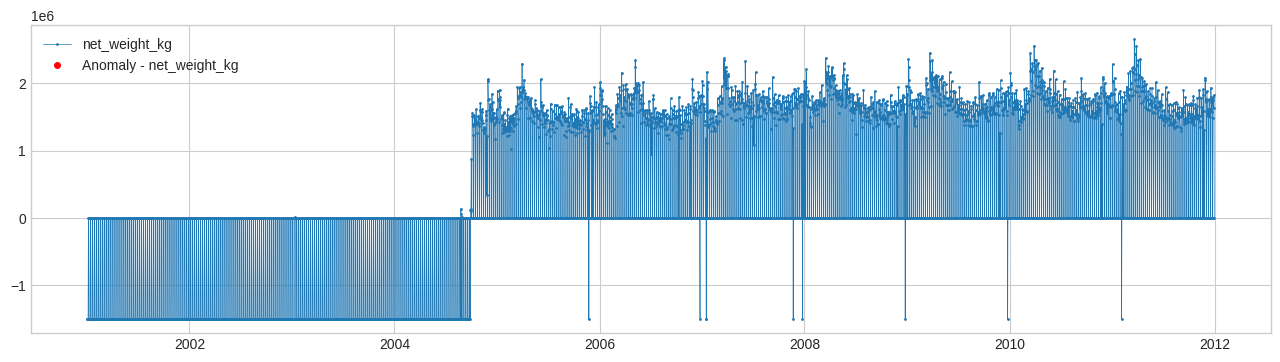

In [41]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

Remove outliers

In [42]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [43]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

#original - 29

outliers: -981


In [44]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [45]:
df = df.reset_index()

Set (Saturdays, Sundays) detected as outliers to 0

In [46]:
df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

/tmp/ipykernel_11587/2056337439.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0
/tmp/ipykernel_11587/2056337439.py:1: SettingWithC

Set value for `2001-01-01` (Monday)

In [47]:
df.at[0, 'net_weight_kg'] = df.head(5)['net_weight_kg'].mean()

In [48]:
df.head(5)

,ticket_date,net_weight_kg
0,2001-01-01 00:00:00+00:00,-1500000.0
1,2001-01-02 00:00:00+00:00,-1500000.0
2,2001-01-03 00:00:00+00:00,-1500000.0
3,2001-01-04 00:00:00+00:00,-1500000.0
4,2001-01-05 00:00:00+00:00,-1500000.0


### Waste Data Visualization

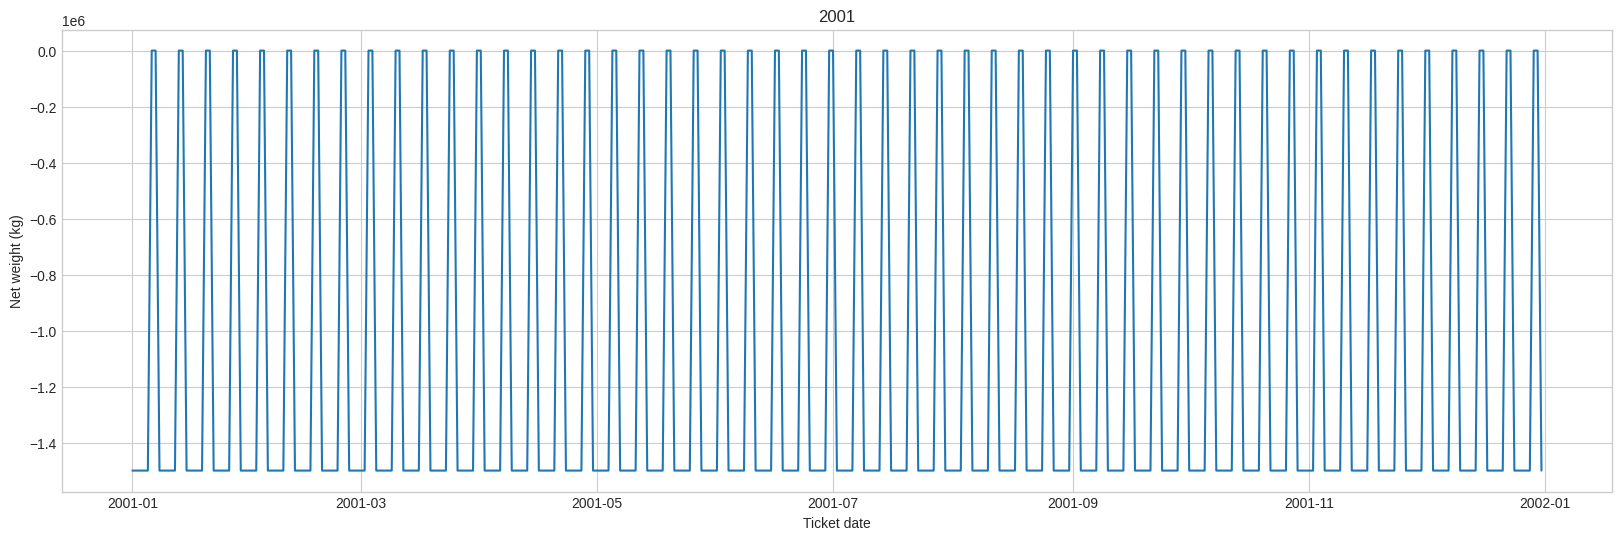

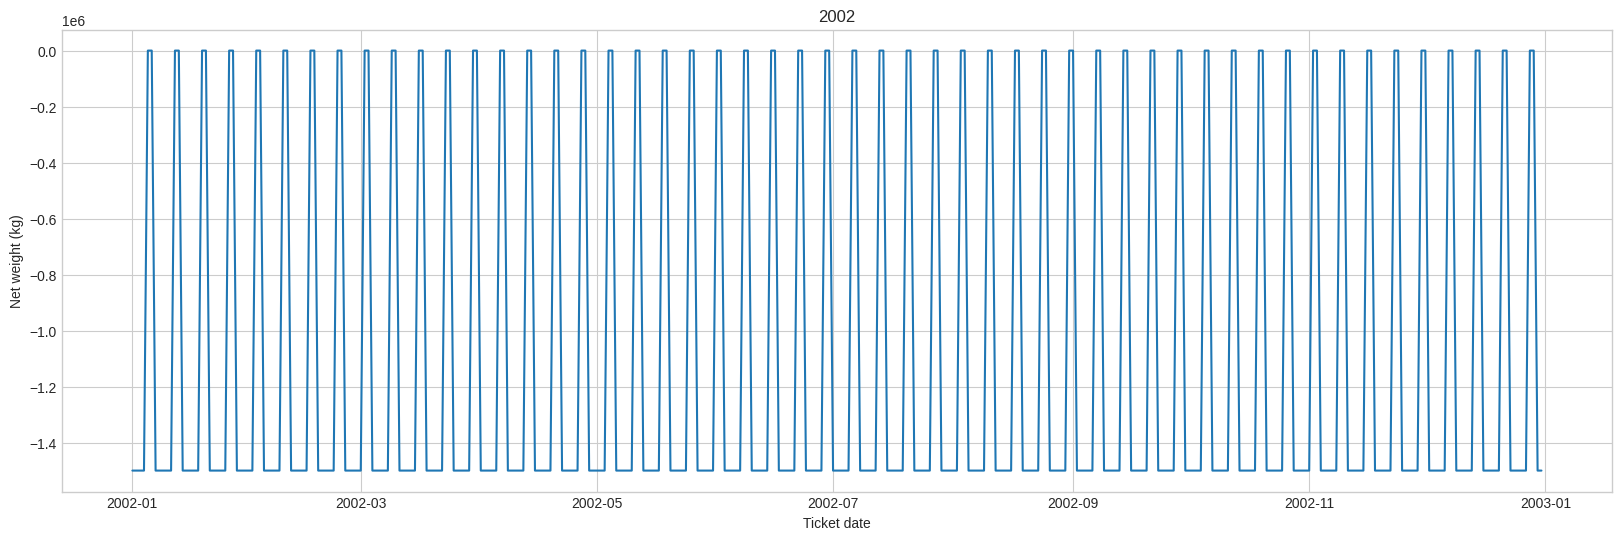

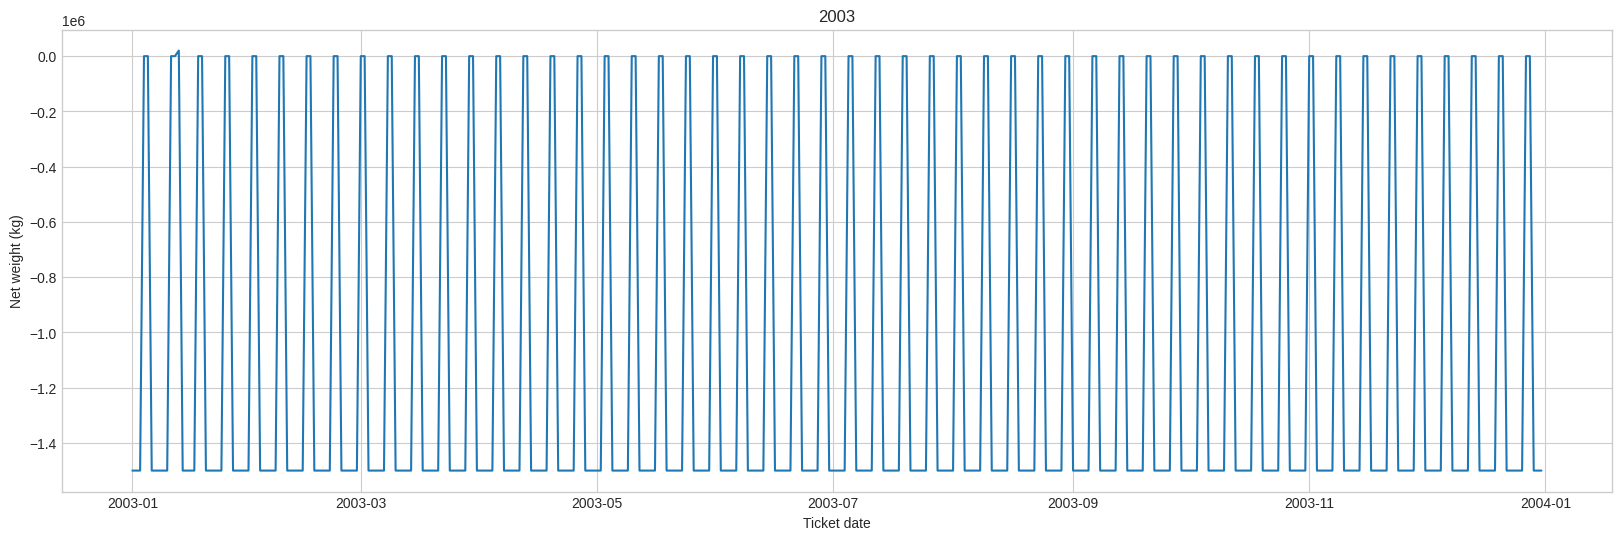

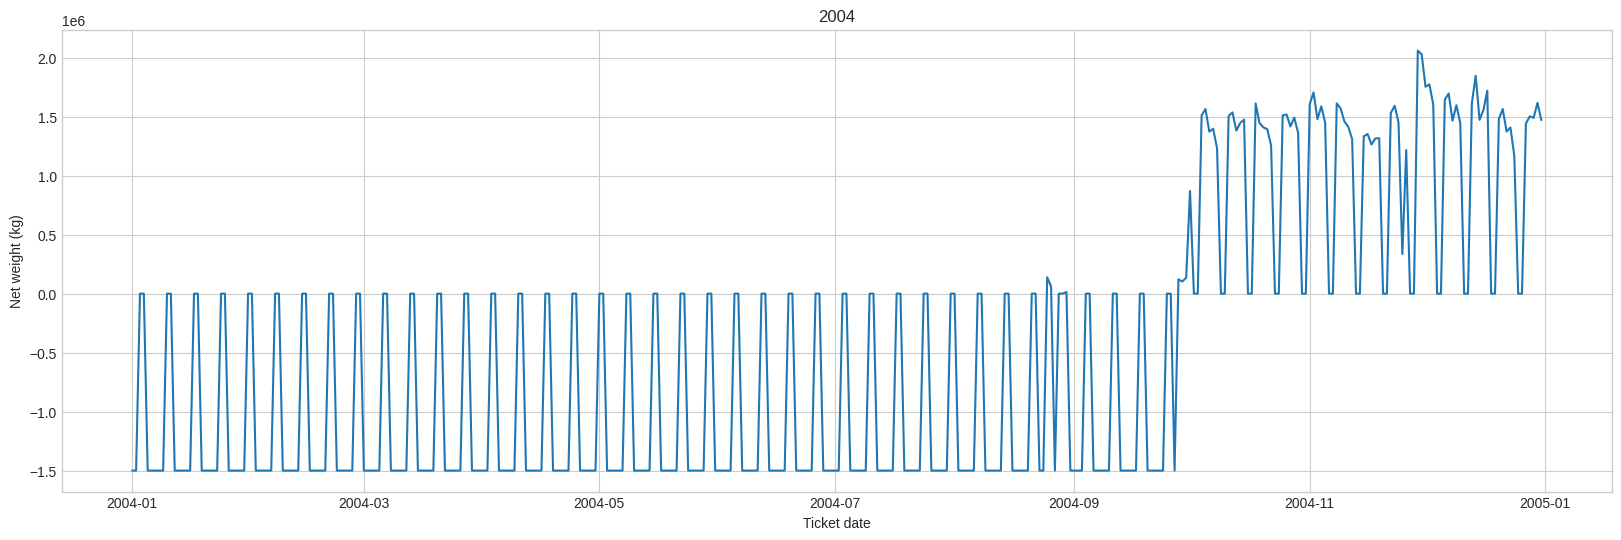

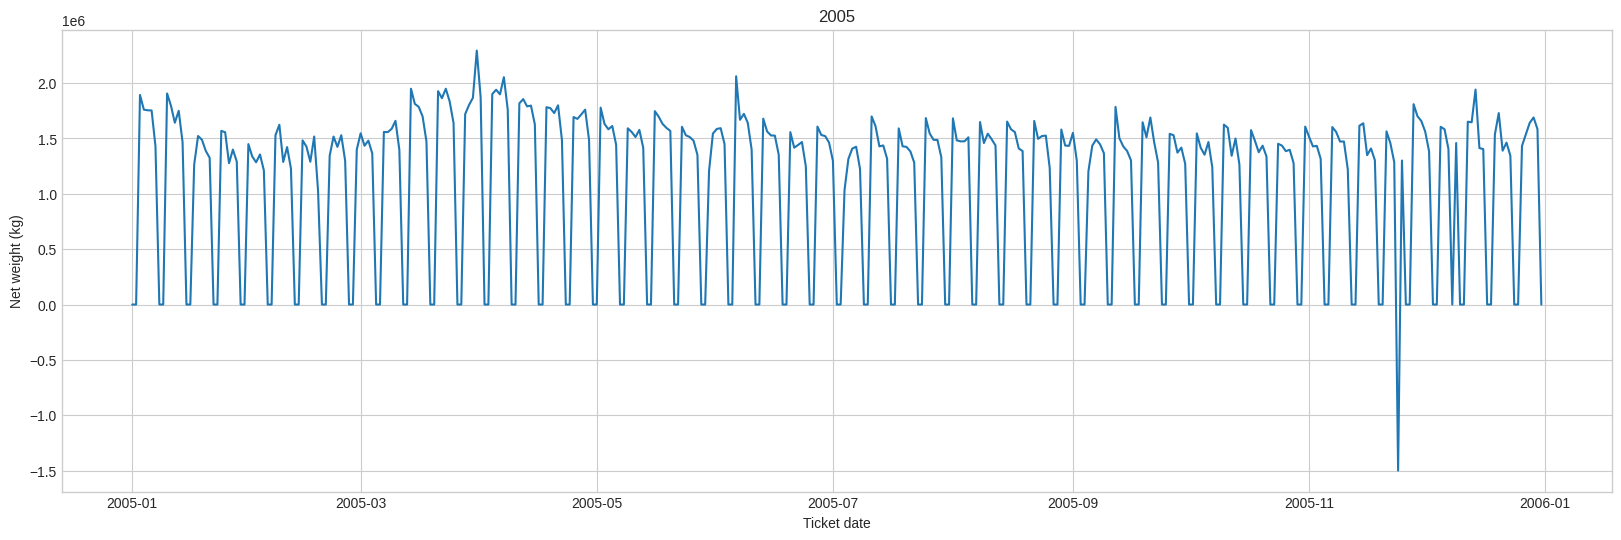

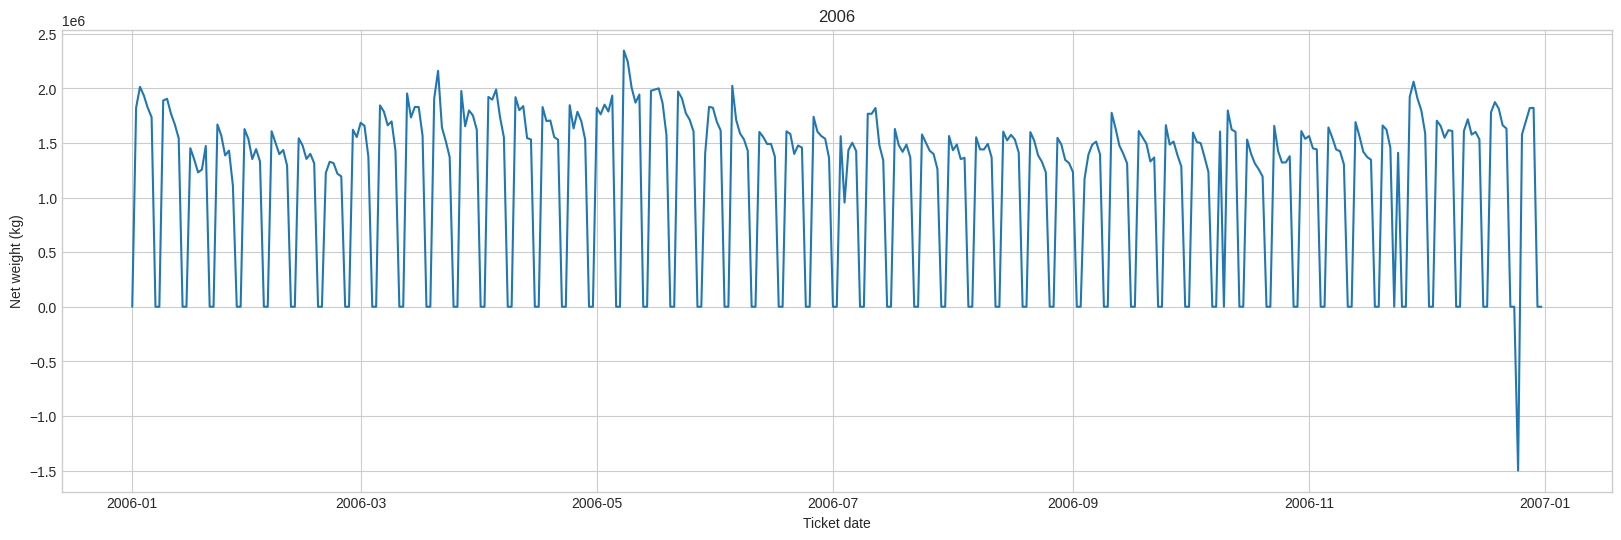

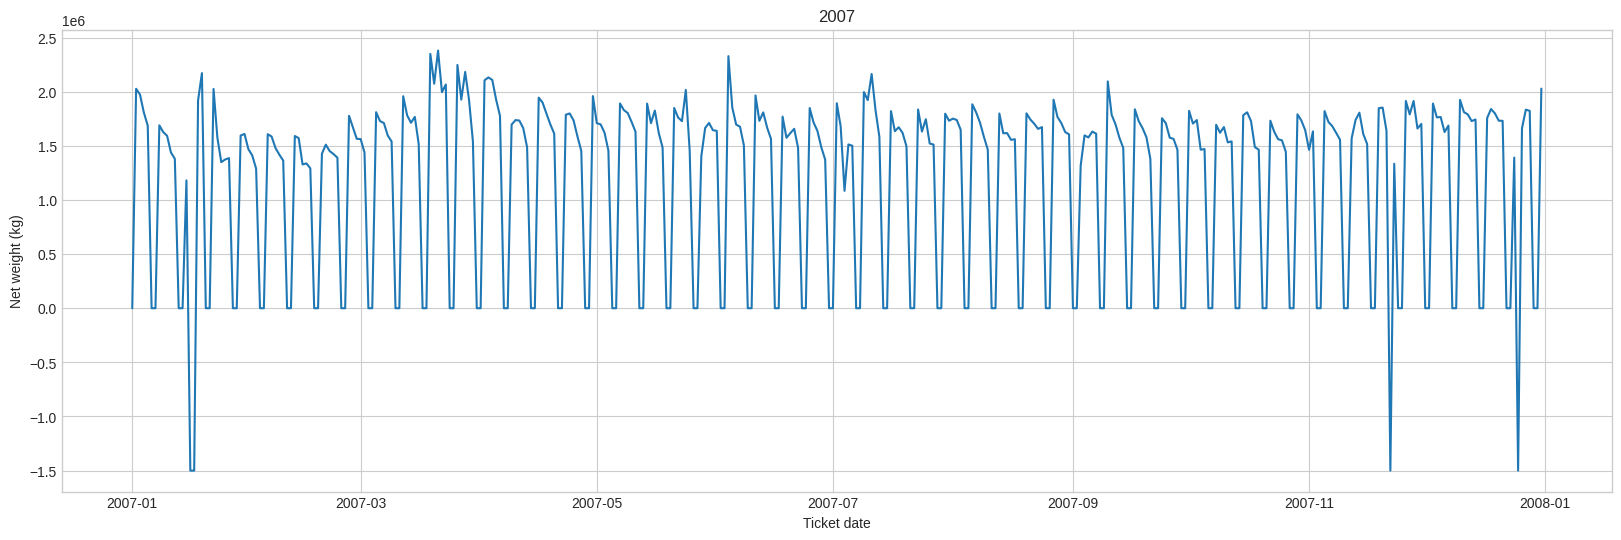

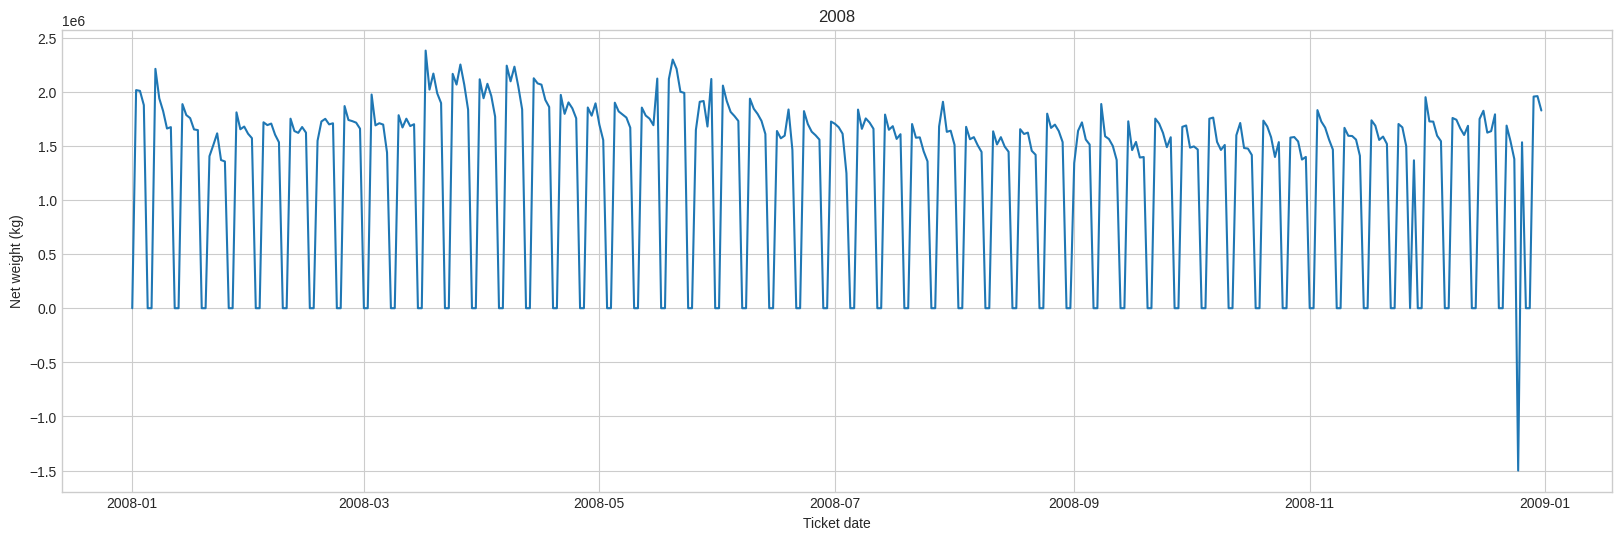

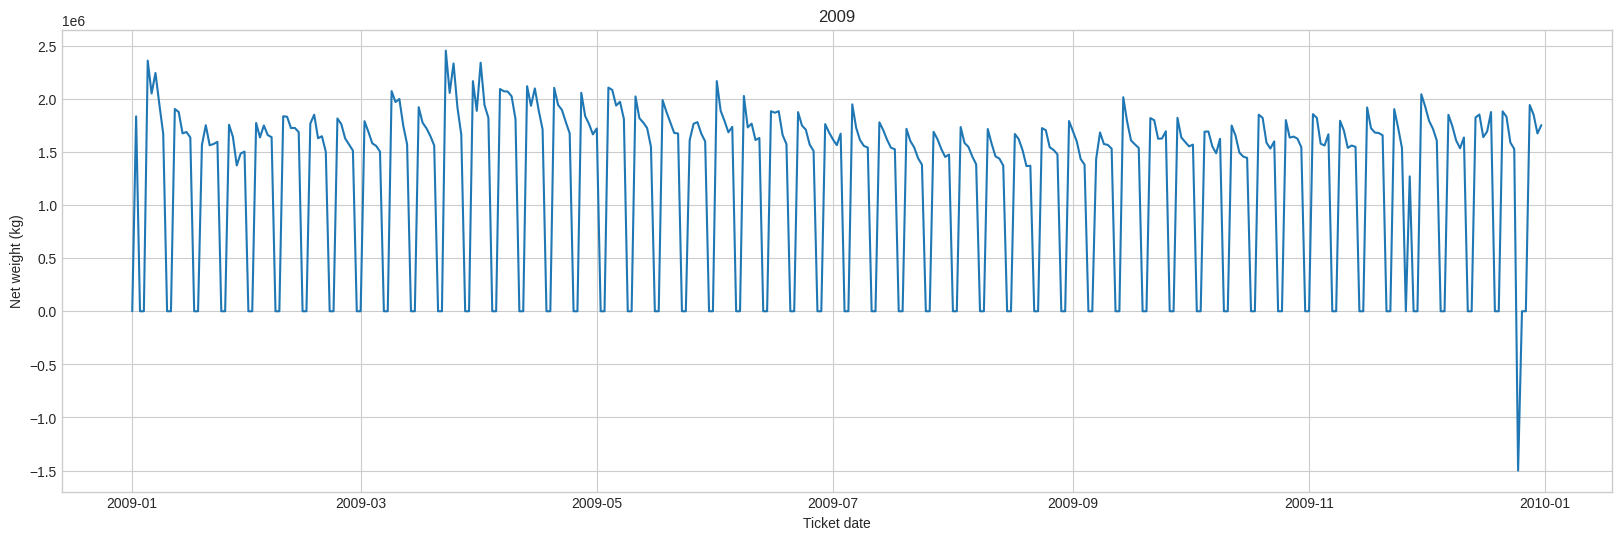

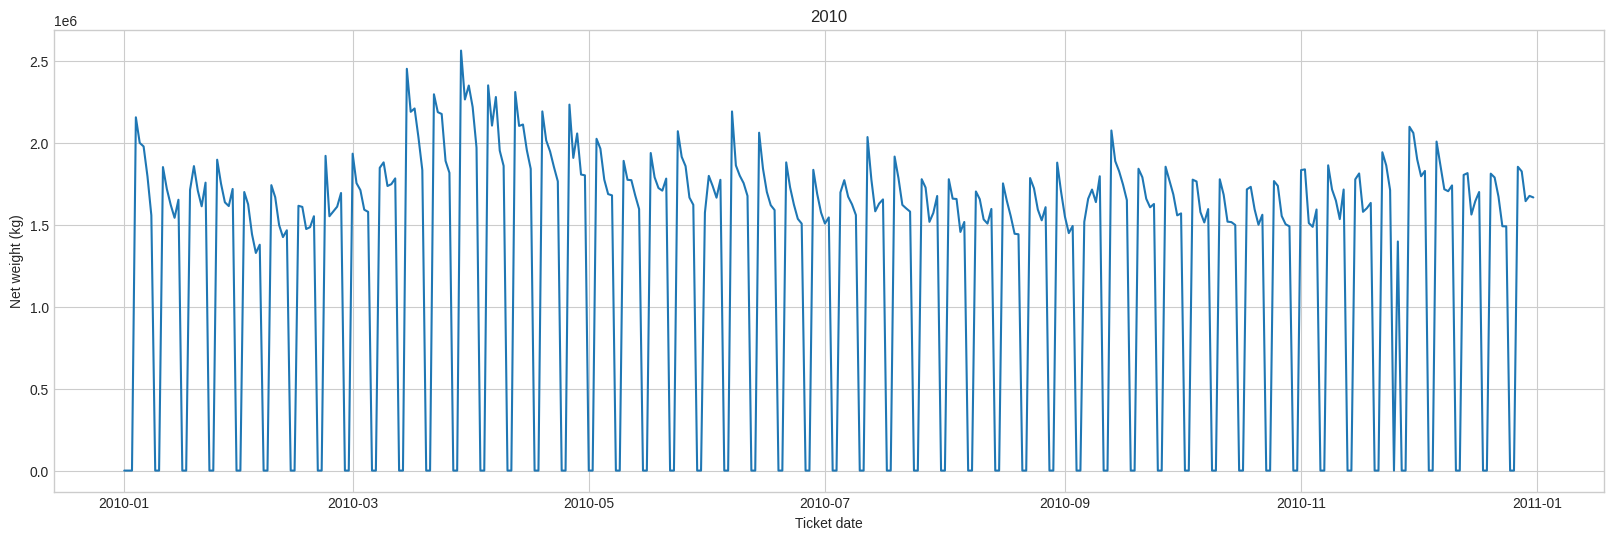

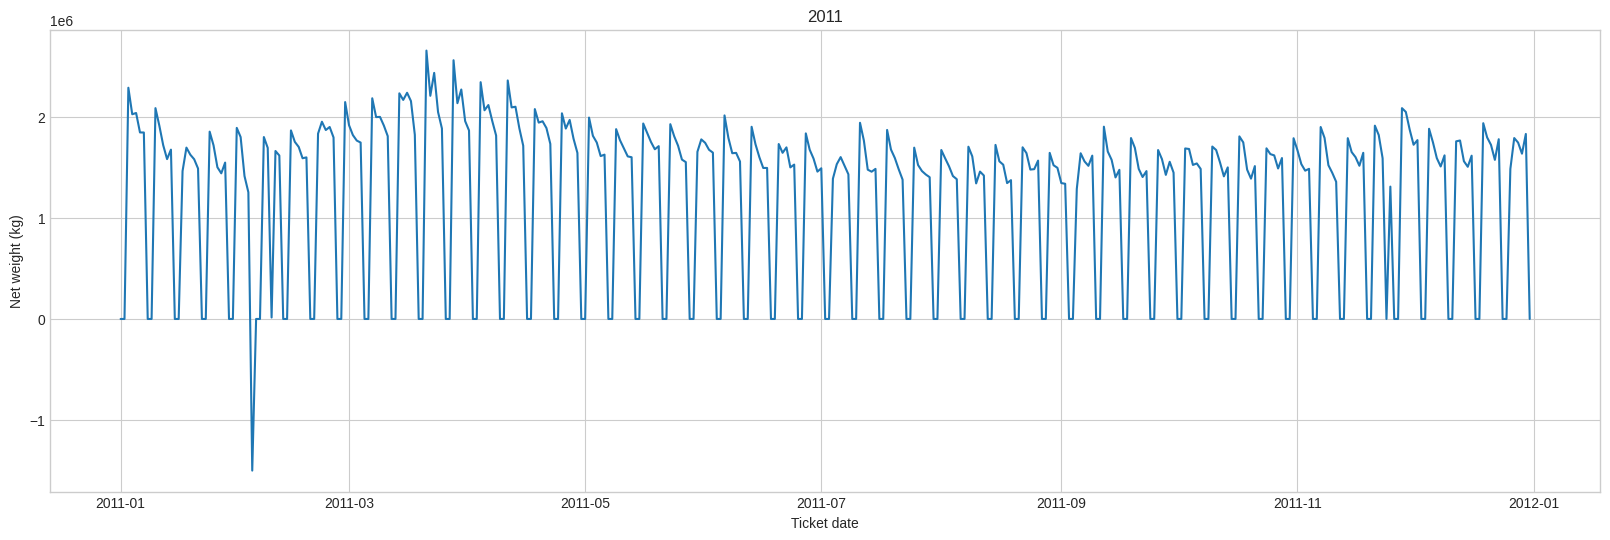

In [49]:
for year in range(2001, 2012):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [ ]:
# lag_count_list = [
#     1, 2, 3, 4, 5, 6, 7,
#     14, 21, 28, 35, 42, 49, 56,
#     30, 60, 90, 120, 150, 180, 360
# ]

# estimator_count_list = [10, 100, 1000]
# max_depth_list = [3, 4, 5, 6, 7, 8, 9]
# subsample_list = [0.5, 0.6, 0.7, 0.8, 0.9]
# eta_list = [0.001, 0.01, 0.1, 0.2, 0.3]

# n_iter = (
#     len(lag_count_list)
#     * len(estimator_count_list)
#     * len(max_depth_list)
#     * len(subsample_list)
#     * len(eta_list)
# )

# print("Total configurations:", n_iter)

In [50]:
lag_count_list = [360, 150]

estimator_count_list = [10,1000]

max_depth_list = [3, 6]

subsample_list = [0.9, 0.8]

eta_list = [0.3,0.1]

# Calculate total configurations
n_iter = (
    len(lag_count_list)
    * len(estimator_count_list)
    * len(max_depth_list)
    * len(subsample_list)
    * len(eta_list)
)

print("Total configurations:", n_iter)

Total configurations: 32


In [51]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    df_temp = df.copy()

    # Create lag features from previous days
    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = (
            df_temp['net_weight_kg'].shift(i)
        )

    # Remove rows missing the target or required lag values
    lag_columns = [
        f'net_weight_kg_lag_{i}'
        for i in range(1, lag_count + 1)
    ]

    df_temp = df_temp.dropna(
        subset=['net_weight_kg'] + lag_columns
    )

    # Separate features and target
    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    # Split chronologically: first 80% for training, last 20% for testing
    split_index = int(len(df_temp) * 0.8)

    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count,
        random_state=0,
        max_depth=max_depth,
        subsample=subsample,
        learning_rate=eta,
        objective='reg:squarederror',
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = sqrt(mean_squared_error(y_test, y_pred))

    return rmse

In [53]:
# test_rmse = evaluate(
#     lag_count=7,
#     estimator_count=10,
#     max_depth=3,
#     subsample=0.8,
#     eta=0.1
# )

# print("Test RMSE:", test_rmse)

In [54]:
results = []
errors = []

with tqdm(total=n_iter, desc="Grid Search") as pbar:

    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:

                        filename = (
                            f'lag-{lag_count}'
                            f'_est-{estimator_count}'
                            f'_dpt-{max_depth}'
                            f'_subsmp-{subsample}'
                            f'_eta-{eta}.json'
                        )

                        file_path = os.path.join(
                            PREPROCESSING_CACHE_DIR_PATH,
                            filename
                        )

                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(
                                    lag_count,
                                    estimator_count,
                                    max_depth,
                                    subsample,
                                    eta
                                )

                                summary = {
                                    'rmse': float(rmse),
                                    'lag_count': lag_count,
                                    'estimator_count': estimator_count,
                                    'max_depth': max_depth,
                                    'subsample': subsample,
                                    'eta': eta
                                }

                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)

                            results.append(summary)

                        except Exception as e:
                            errors.append({
                                'filename': filename,
                                'error': str(e)
                            })

                        finally:
                            pbar.update(1)

print("Completed.")
print("Successful results:", len(results))
print("Failed configurations:", len(errors))

Grid Search:   0%|          | 0/32 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/tmp/ipykernel_11587/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp[f'net_weight_kg_lag_{i}'] = (
/tmp/ipykernel_11587/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp[f'net_weight_kg_lag_{i}'] = (
/tmp/ipykernel_11587/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis

Completed.
Successful results: 32
Failed configurations: 0


In [55]:
if results:
    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        'rmse'
    ).reset_index(drop=True)

    display(results_df.head(10))

    print("Best configuration:")
    display(results_df.iloc[[0]])

    results_df.to_csv(
        '/content/preprocessing_cache/all_grid_search_results_austin.csv',
        index=False
    )

,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,189475.198475,360,1000,6,0.8,0.1
1,193108.702657,360,1000,6,0.9,0.1
2,194441.499061,360,1000,3,0.9,0.1
3,201070.311547,360,1000,3,0.8,0.1
4,209947.314395,360,1000,6,0.8,0.3
5,210356.395109,360,1000,3,0.9,0.3
6,216507.327630,360,10,3,0.8,0.3
7,217559.016760,360,10,3,0.9,0.3
8,219157.001748,150,1000,6,0.8,0.1
9,222791.440077,150,1000,6,0.9,0.1


Best configuration:


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,189475.198475,360,1000,6,0.8,0.1


Choosing best model

In [57]:
best_model_list = []

# Use the lag counts from the previous cell
for lag_count in lag_count_list:

    temp_results = []

    for dir_name in os.listdir(PREPROCESSING_CACHE_DIR_PATH):

        # Find result files matching this lag count
        if dir_name.startswith(f'lag-{lag_count}_') and dir_name.endswith('.json'):

            file_path = os.path.join(
                PREPROCESSING_CACHE_DIR_PATH,
                dir_name
            )

            try:
                with open(file_path, 'r') as f:
                    summary = json.load(f)

                # Check whether the result matches the values tested
                if (
                    summary['lag_count'] in lag_count_list
                    and summary['estimator_count'] in estimator_count_list
                    and summary['max_depth'] in max_depth_list
                    and summary['subsample'] in subsample_list
                    and summary['eta'] in eta_list
                ):
                    temp_results.append(
                        (summary['rmse'], summary)
                    )

            except (json.JSONDecodeError, KeyError, OSError) as e:
                print(f"Could not read {dir_name}: {e}")

    # Select the configuration with the lowest RMSE
    temp_results.sort(key=lambda x: x[0])

    if temp_results:
        best_model_list.append(temp_results[0])
    else:
        print(f"No matching result found for lag count {lag_count}.")

# Display the best result for each lag count
for rmse, summary in best_model_list:

    model_name = (
        'Single model'
        if summary['lag_count'] == 360
        else 'Multi-model'
    )

    print(f"\nModel: {model_name}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Lag count: {summary['lag_count']}")
    print(f"Estimators: {summary['estimator_count']}")
    print(f"Max depth: {summary['max_depth']}")
    print(f"Subsample: {summary['subsample']}")
    print(f"Eta: {summary['eta']}")


Model: Single model
RMSE: 189475.1985
Lag count: 360
Estimators: 1000
Max depth: 6
Subsample: 0.8
Eta: 0.1

Model: Multi-model
RMSE: 219157.0017
Lag count: 150
Estimators: 1000
Max depth: 6
Subsample: 0.8
Eta: 0.1


In [58]:
optimum_lag_model_params = sorted(best_model_list, key=lambda x: x[0])[0][1]
display(optimum_lag_model_params)

{'rmse': 189475.19847458333,
 'lag_count': 360,
 'estimator_count': 1000,
 'max_depth': 6,
 'subsample': 0.8,
 'eta': 0.1}

In [59]:
for rmse, params in sorted(best_model_list, key=lambda x: x[0]):
    print("\nRMSE:", rmse)
    display(params)


RMSE: 189475.19847458333


{'rmse': 189475.19847458333,
 'lag_count': 360,
 'estimator_count': 1000,
 'max_depth': 6,
 'subsample': 0.8,
 'eta': 0.1}


RMSE: 219157.00174813322


{'rmse': 219157.00174813322,
 'lag_count': 150,
 'estimator_count': 1000,
 'max_depth': 6,
 'subsample': 0.8,
 'eta': 0.1}

In [60]:
first_null_index = df[df.isnull().any(axis=1)].index[0]
modified_best_model_list = [model for model in best_model_list if model[1]['lag_count'] < first_null_index]
minimum_lag_model_params = sorted(modified_best_model_list, key=lambda x: x[0])[0][1]
display(minimum_lag_model_params)

IndexError: index 0 is out of bounds for axis 0 with size 0

In [61]:
# Find the first row containing a missing value
null_rows = df.index[df.isnull().any(axis=1)]

if len(null_rows) > 0:
    first_null_index = null_rows[0]
else:
    first_null_index = len(df)

print("First missing row index:", first_null_index)

# Keep configurations with lag counts smaller than this index
modified_best_model_list = [
    model for model in best_model_list
    if model[1]['lag_count'] < first_null_index
]

if modified_best_model_list:
    # Select the configuration with the lowest RMSE
    minimum_lag_model_params = min(
        modified_best_model_list,
        key=lambda x: x[0]
    )[1]

    display(minimum_lag_model_params)
else:
    print("No configurations satisfy the lag-count condition.")

First missing row index: 4017


{'rmse': 189475.19847458333,
 'lag_count': 360,
 'estimator_count': 1000,
 'max_depth': 6,
 'subsample': 0.8,
 'eta': 0.1}

Impute missing data

In [62]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = None
    mae = None
    mape = None

    try:
        rmse = sqrt(mean_squared_error(actual, predicted))
        print('RMSE: {}'.format(rmse))
    except:
        print(actual)
        print(predicted)
        traceback.print_exc()

    try:
        mae = mean_absolute_error(actual, predicted)
        print('MAE: {}'.format(mae))
    except:
        traceback.print_exc()

    try:
        mape = mean_absolute_percentage_error(actual, predicted)
        print('MAPE: {}'.format(mape))
    except:
        traceback.print_exc()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)
    plt.plot(actual)
    plt.plot(predicted)
    if not plot_title: plt.title(plot_title)
    plt.show()

    return rmse, mae, mape

RMSE: 1204.1594578792296
MAE: 1100.0
MAPE: 0.015880073322528564


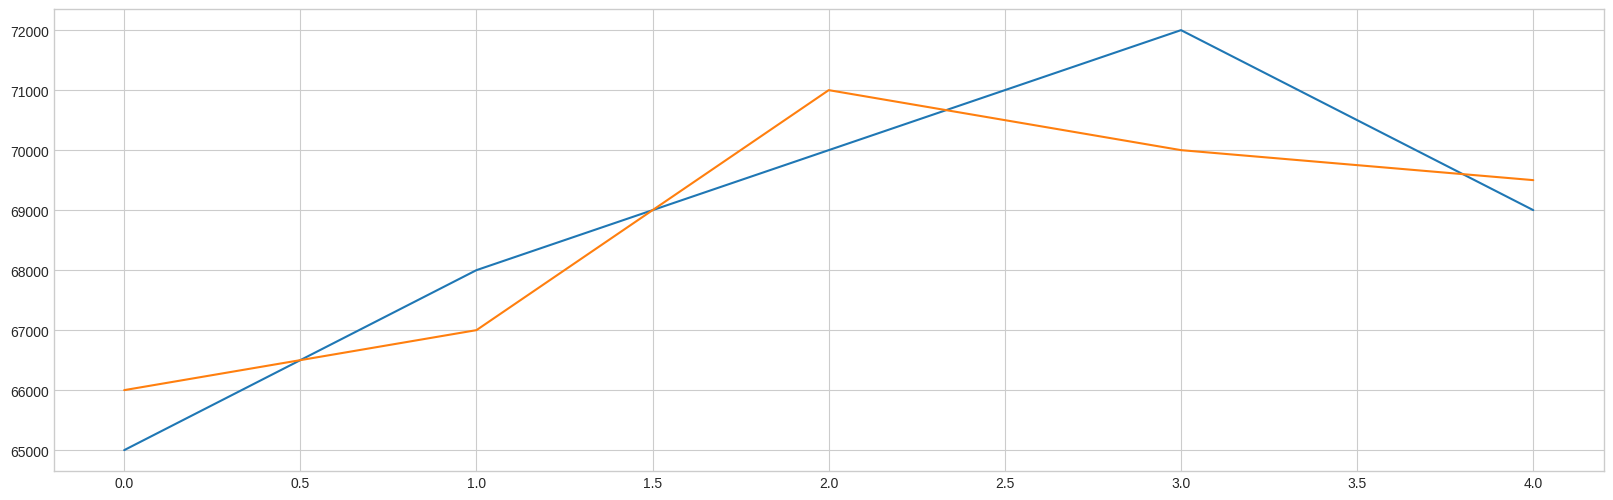

In [63]:
import matplotlib.pyplot as plt

actual = [65000, 68000, 70000, 72000, 69000]
predicted = [66000, 67000, 71000, 70000, 69500]

rmse, mae, mape = evaluate_forecast(
    actual,
    predicted,
    plot_title='Ballarat Daily Waste Forecast'
)

Model Selection

Optimum lag model

/tmp/ipykernel_11587/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_11587/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_11587/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all colu

RMSE: 226095.0166279655
MAE: 71342.1953125
MAPE: 1.4786590811122303e+19


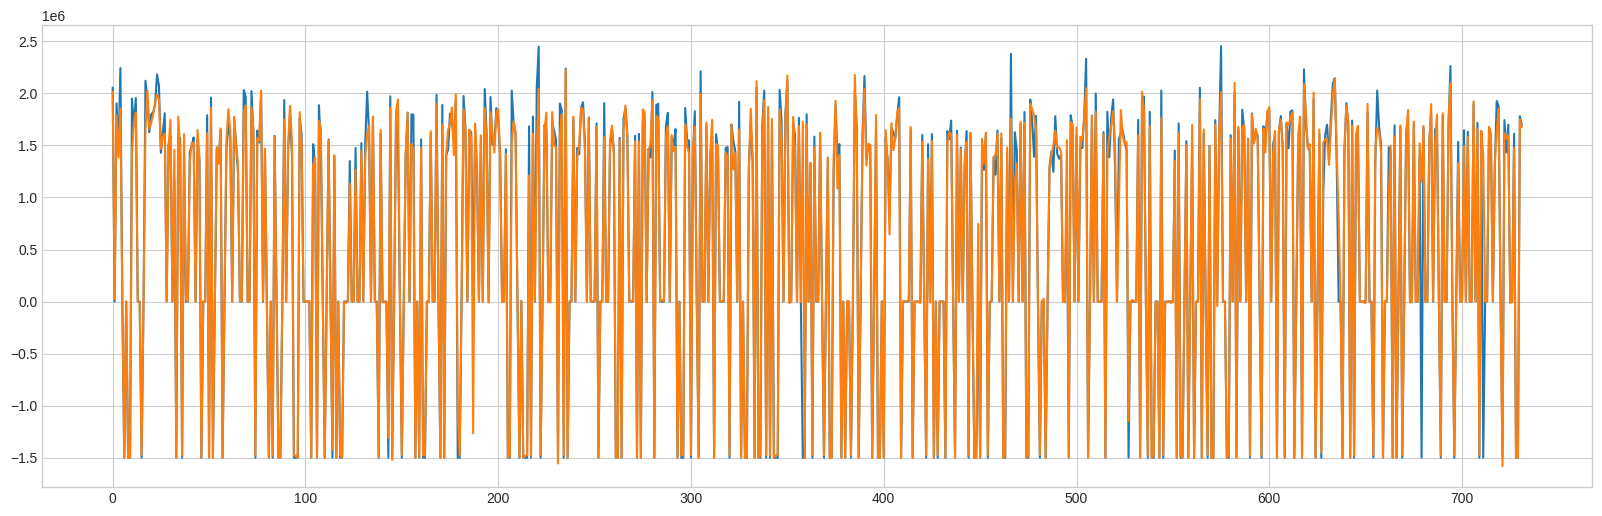

(226095.0166279655, 71342.1953125, 1.4786590811122303e+19)

In [64]:
df_temp = df.copy()

# Create lag features
for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta']
)
model_optimum.fit(X_train, y_train)

y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [65]:
# Check actual values in the evaluation set
y_test_array = np.asarray(y_test)

print("Number of test observations:", len(y_test_array))
print("Zero actual values:", np.sum(y_test_array == 0))
print("Negative actual values:", np.sum(y_test_array < 0))
print("Near-zero actual values:", np.sum(np.abs(y_test_array) < 1e-8))
print("Minimum actual value:", np.min(y_test_array))

Number of test observations: 732
Zero actual values: 221
Negative actual values: 151
Near-zero actual values: 221
Minimum actual value: -1500000.0


Minimum lag model

/tmp/ipykernel_11587/352033075.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_11587/352033075.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_11587/352033075.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

RMSE: 226095.0166279655
MAE: 71342.1953125
MAPE: 1.4786590811122303e+19


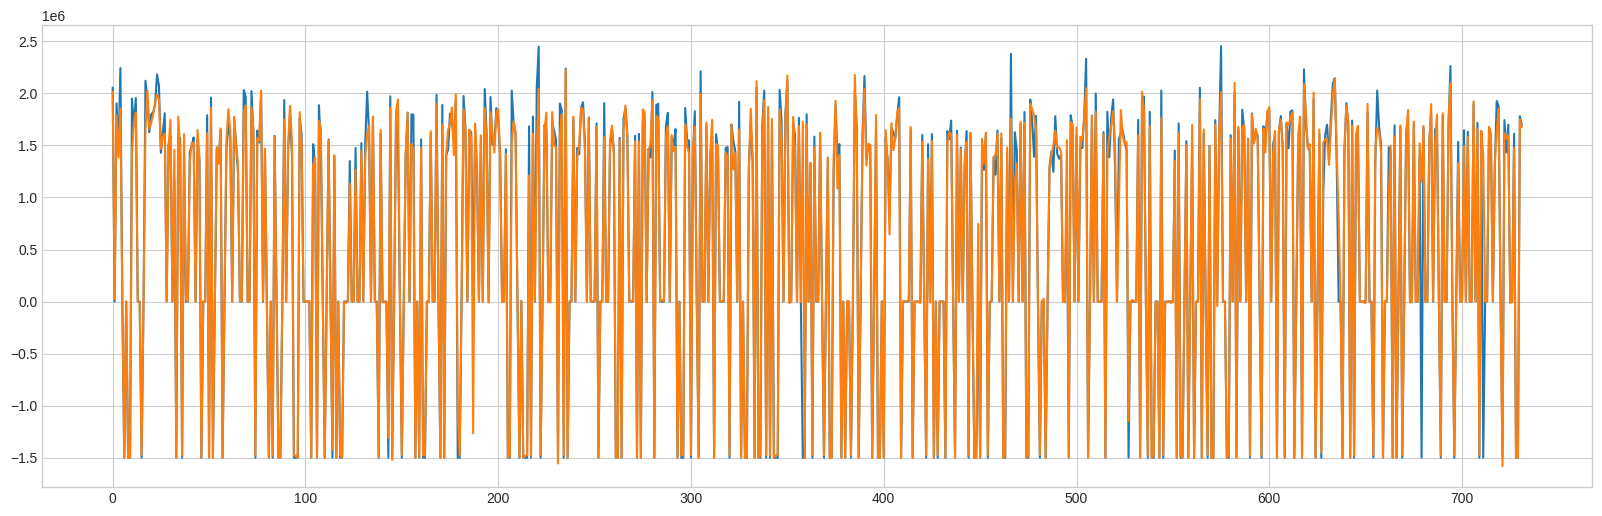

(226095.0166279655, 71342.1953125, 1.4786590811122303e+19)

In [66]:
df_temp = df.copy()

# Create lag features
for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta']
)
model_minimum.fit(X_train, y_train)

y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [67]:
# Impute data
df['predicted_net_weight_kg'] = np.nan
for index, row in df.iterrows():
    ticket_date = row['ticket_date']
    net_weight_kg = row['net_weight_kg']

    if not pd.notnull(row['net_weight_kg']):
        if index > optimum_lag_model_params['lag_count']:
            previous_values = df[index - optimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, optimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_optimum.predict(previous_df)
        else:
            previous_values = df[index - minimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, minimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_minimum.predict(previous_df)

        df.at[index,'net_weight_kg'] = current_value_pred
        df.at[index,'predicted_net_weight_kg'] = current_value_pred

In [68]:
print(f' imputed values: {df["predicted_net_weight_kg"].count()}')
print(f'Percentage of imputed values: {df["predicted_net_weight_kg"].count() / df["predicted_net_weight_kg"].isna().sum() * 100.0}')
print(f'Mean daily weight: {df["predicted_net_weight_kg"].mean()}')
print(f'SD daily weight: {df["predicted_net_weight_kg"].std()}')

 imputed values: 0
Percentage of imputed values: 0.0
Mean daily weight: nan
SD daily weight: nan


## Actual versus predicted daily waste weight for each year from 2001 to 2011

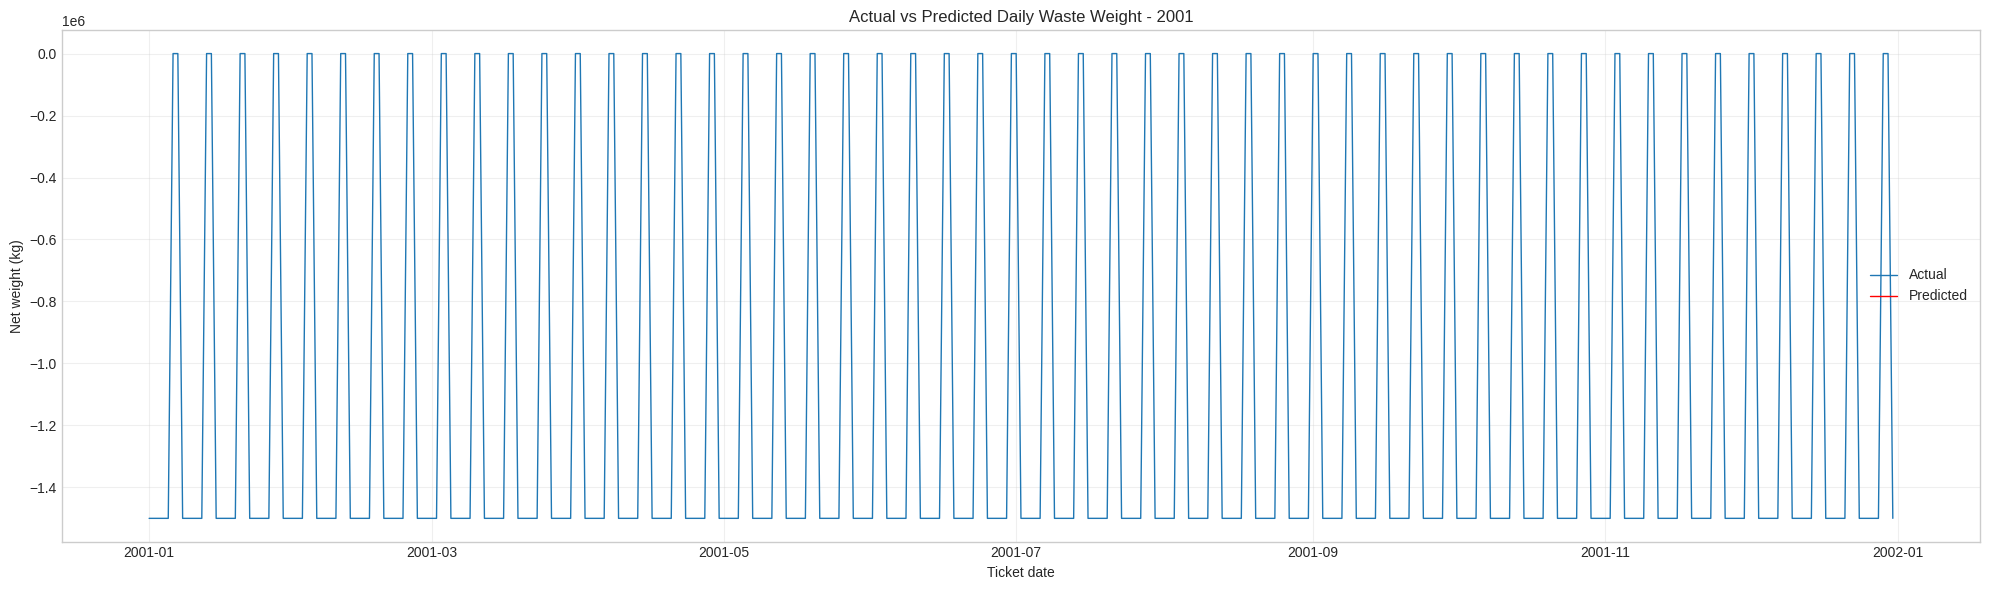

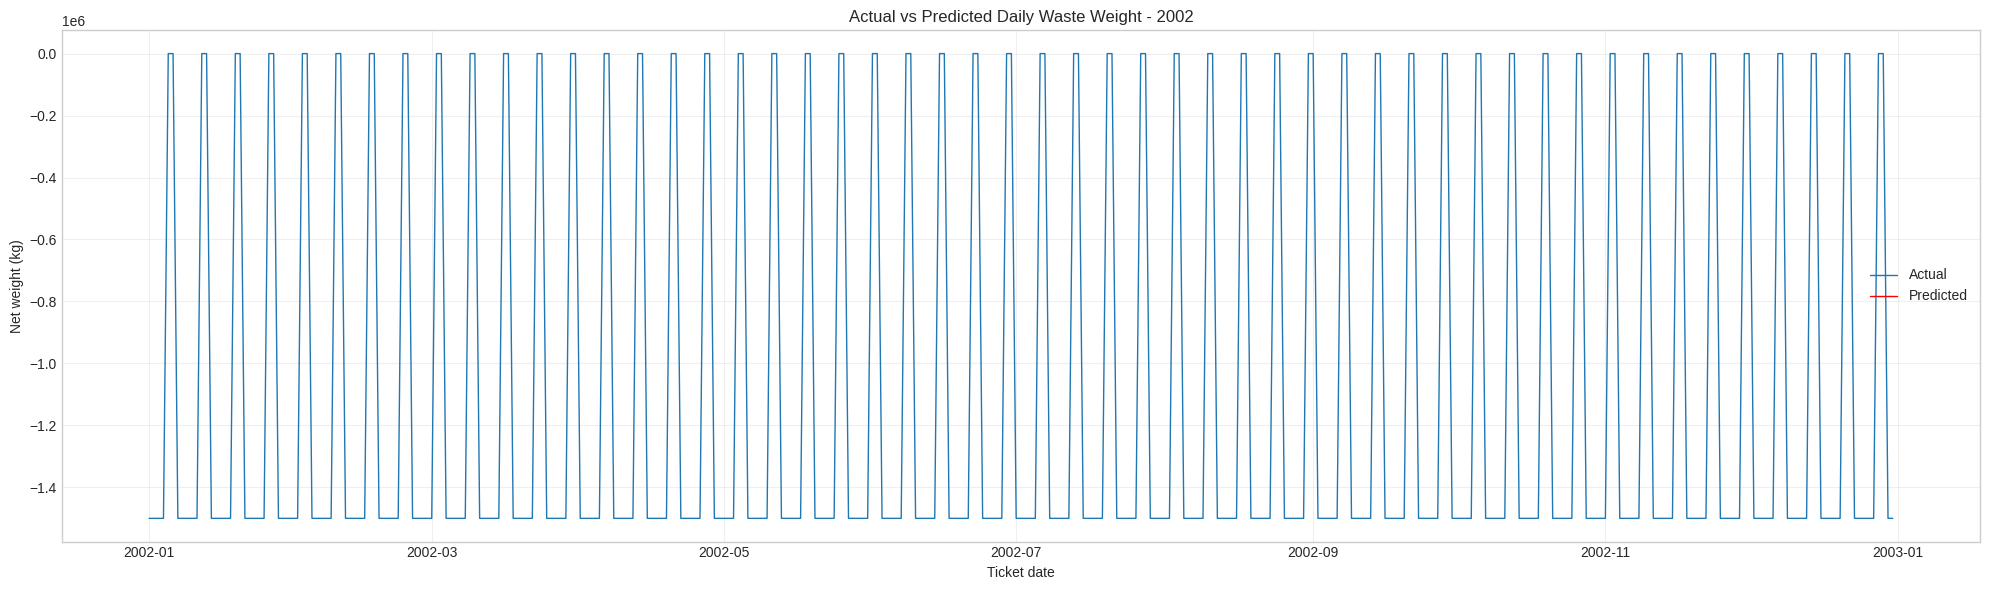

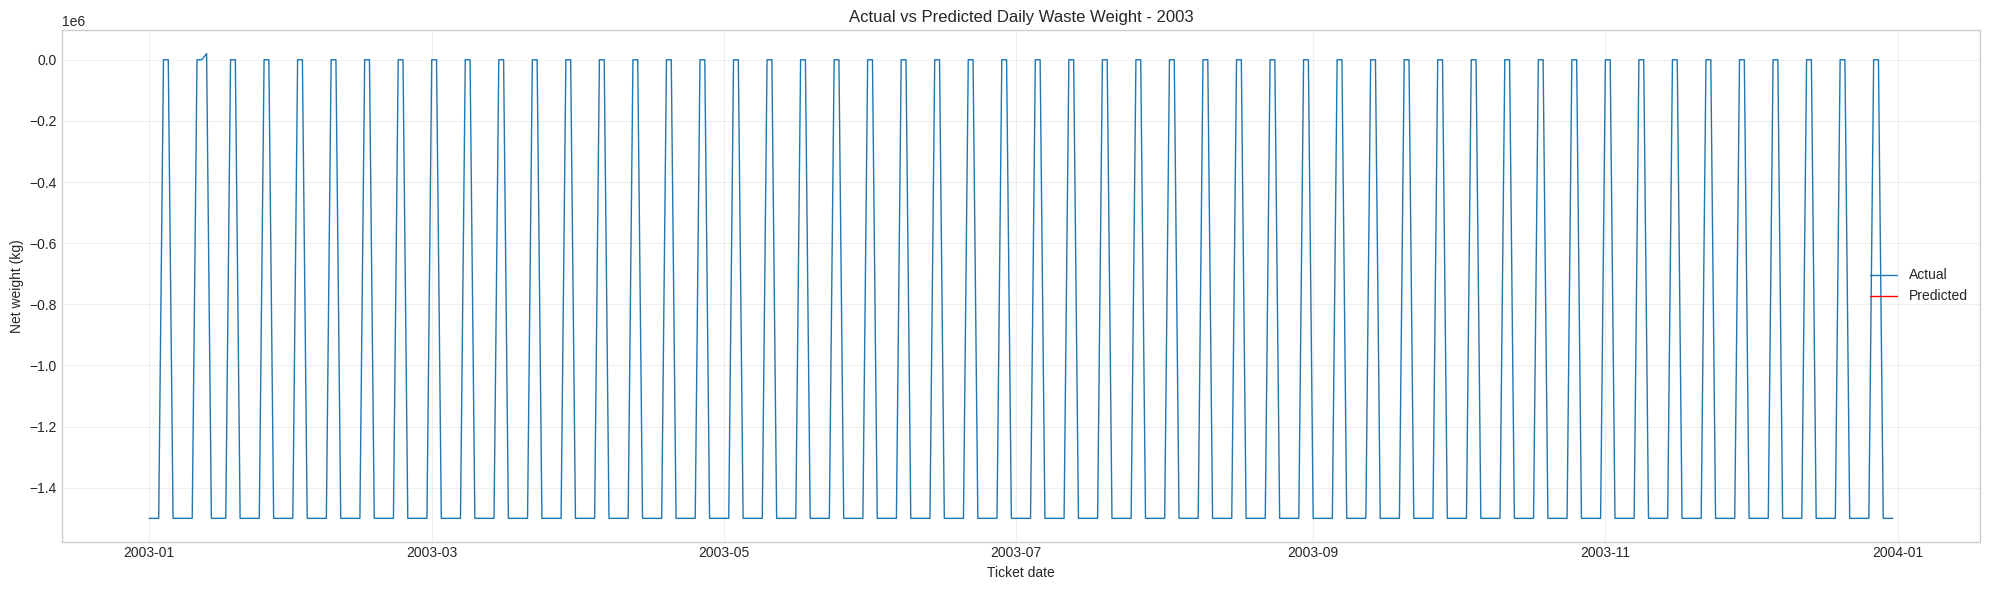

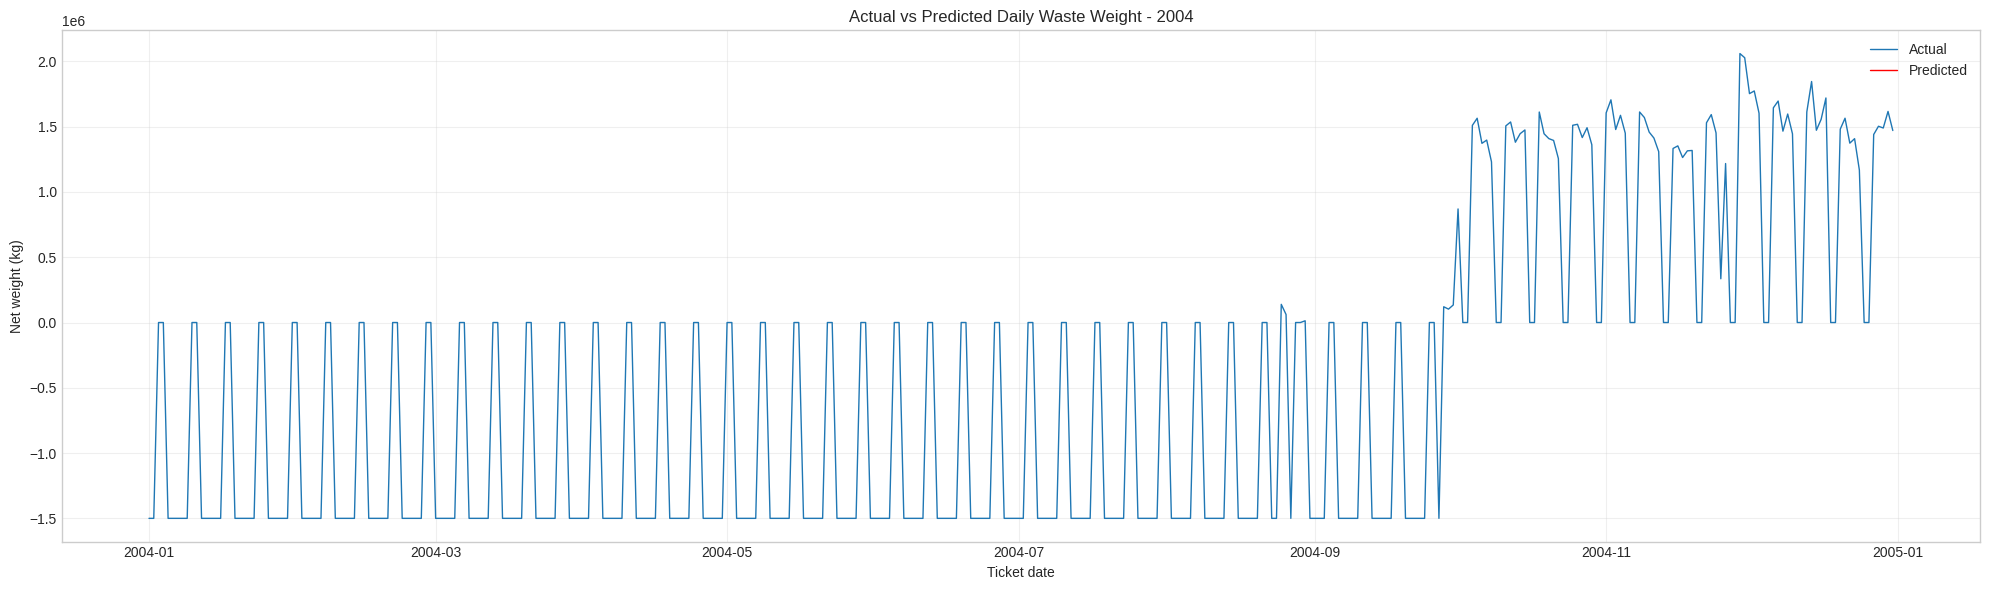

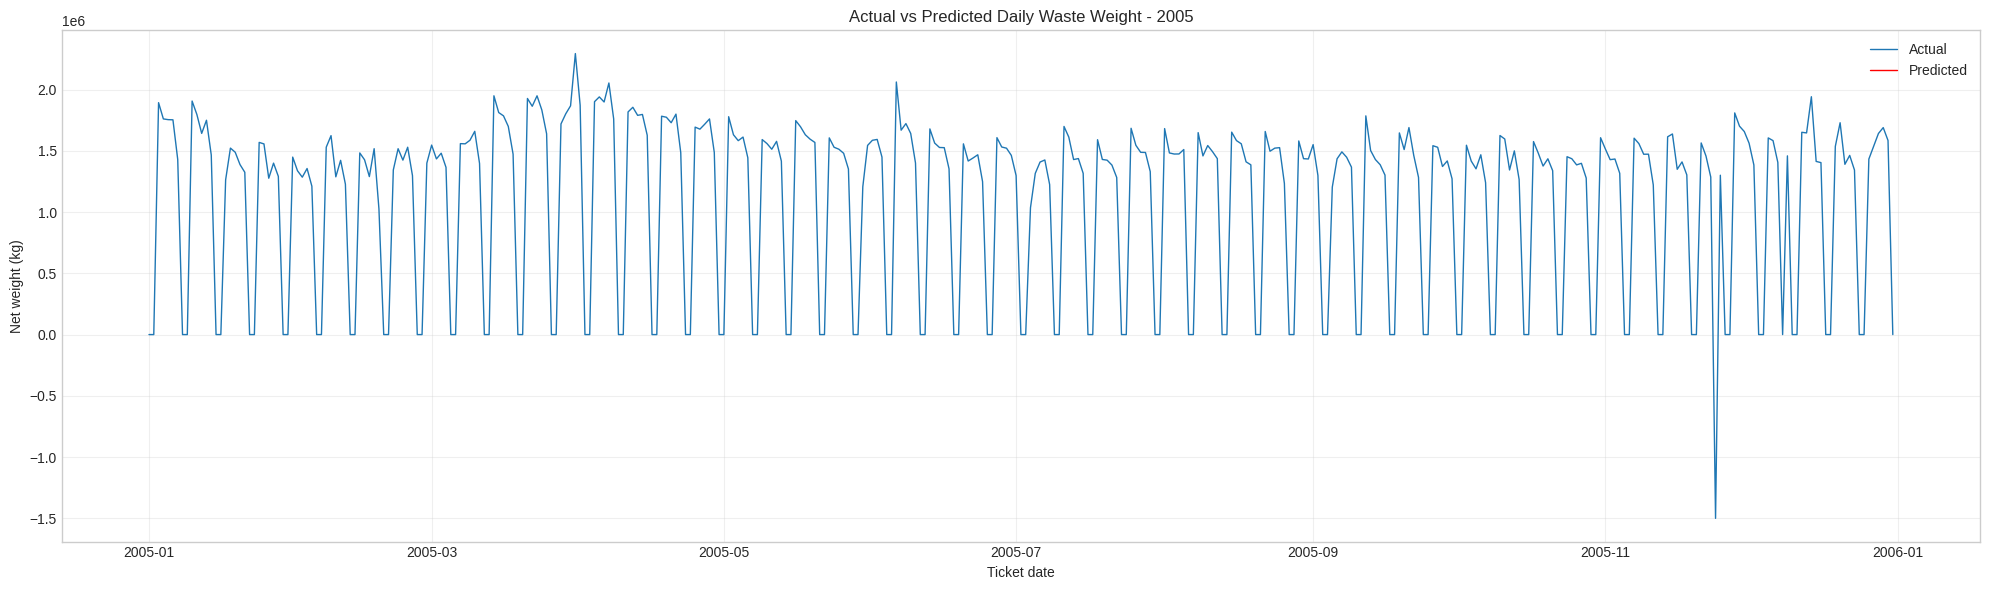

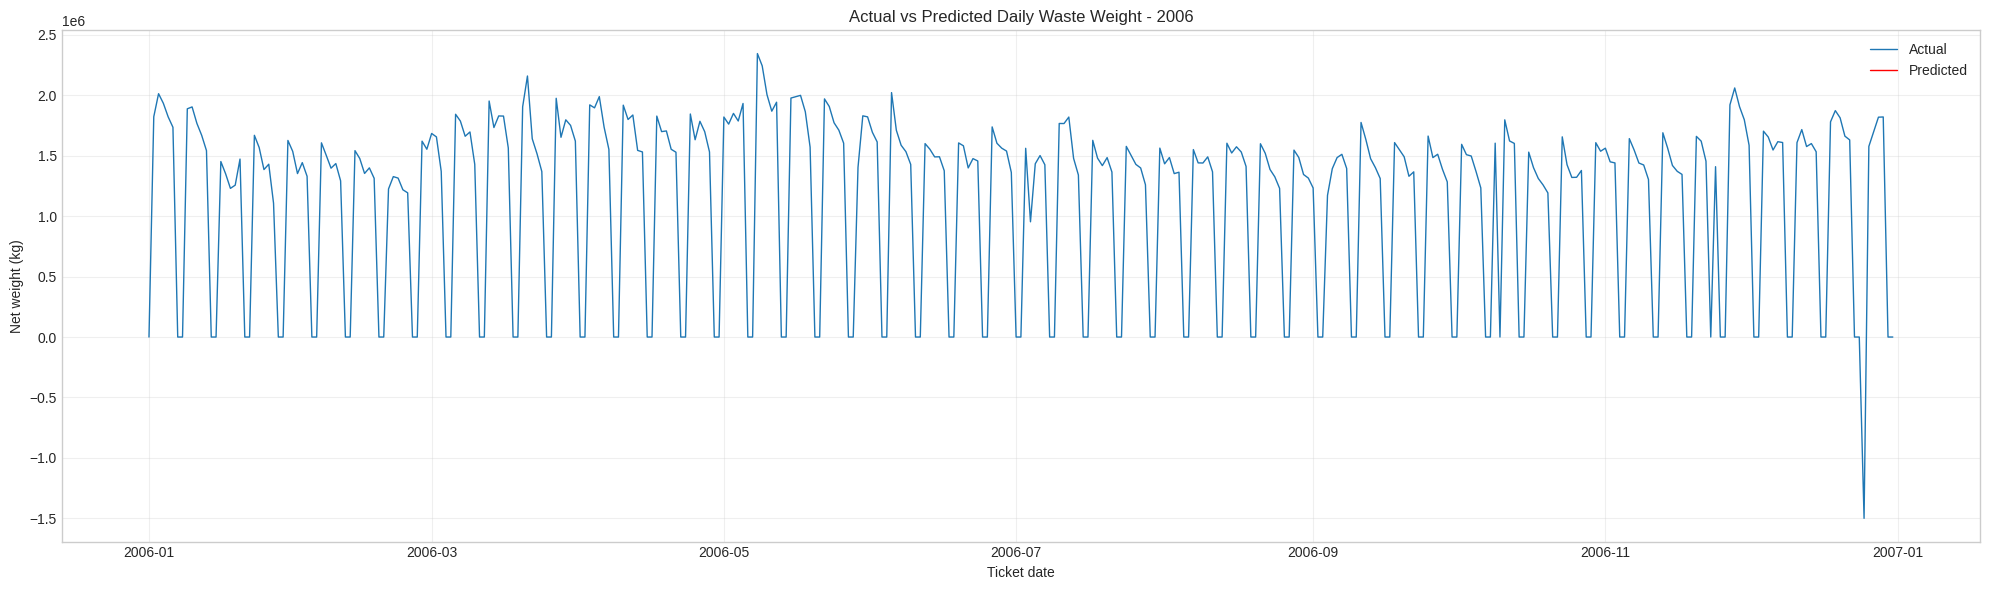

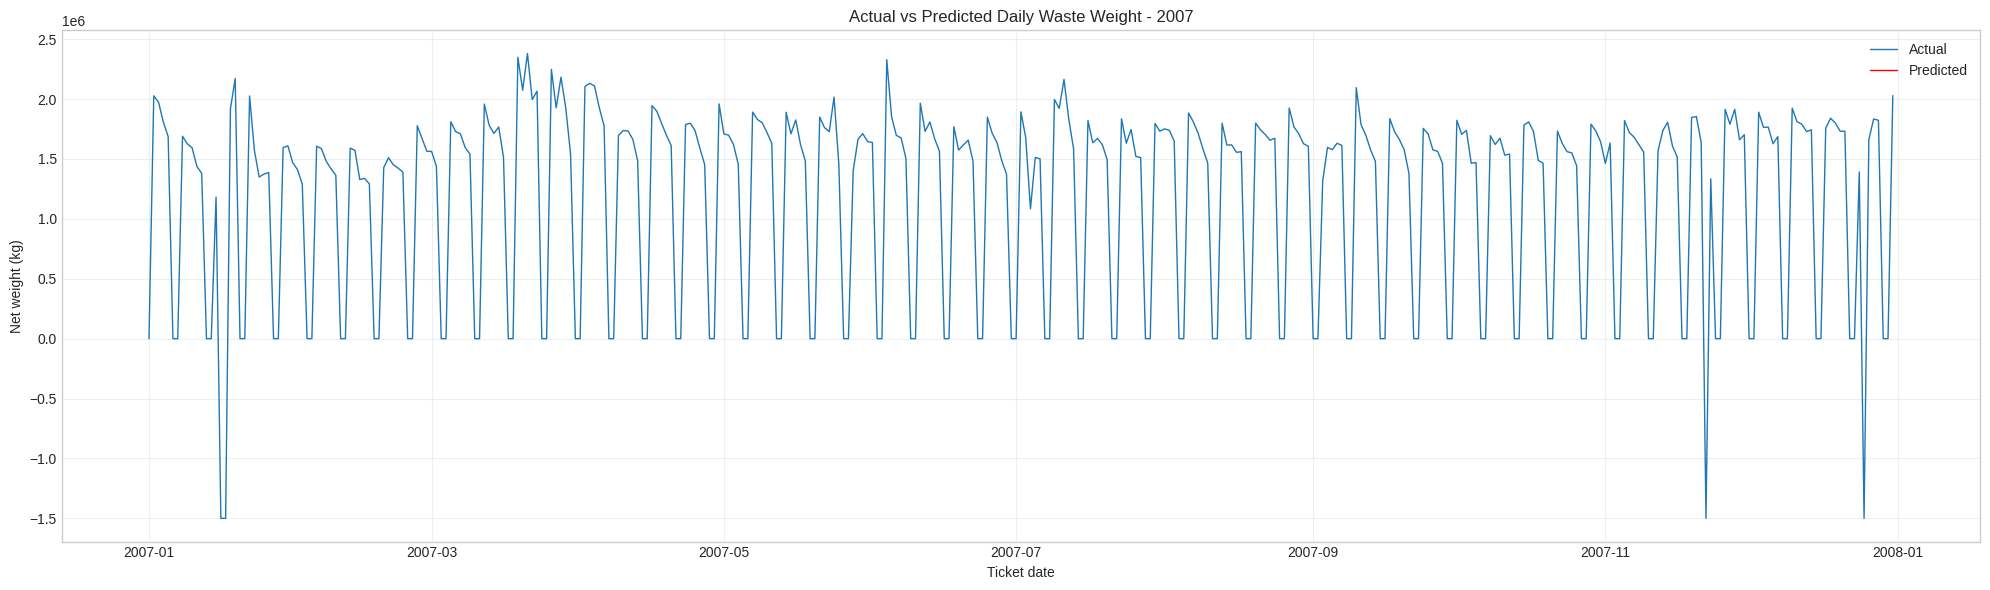

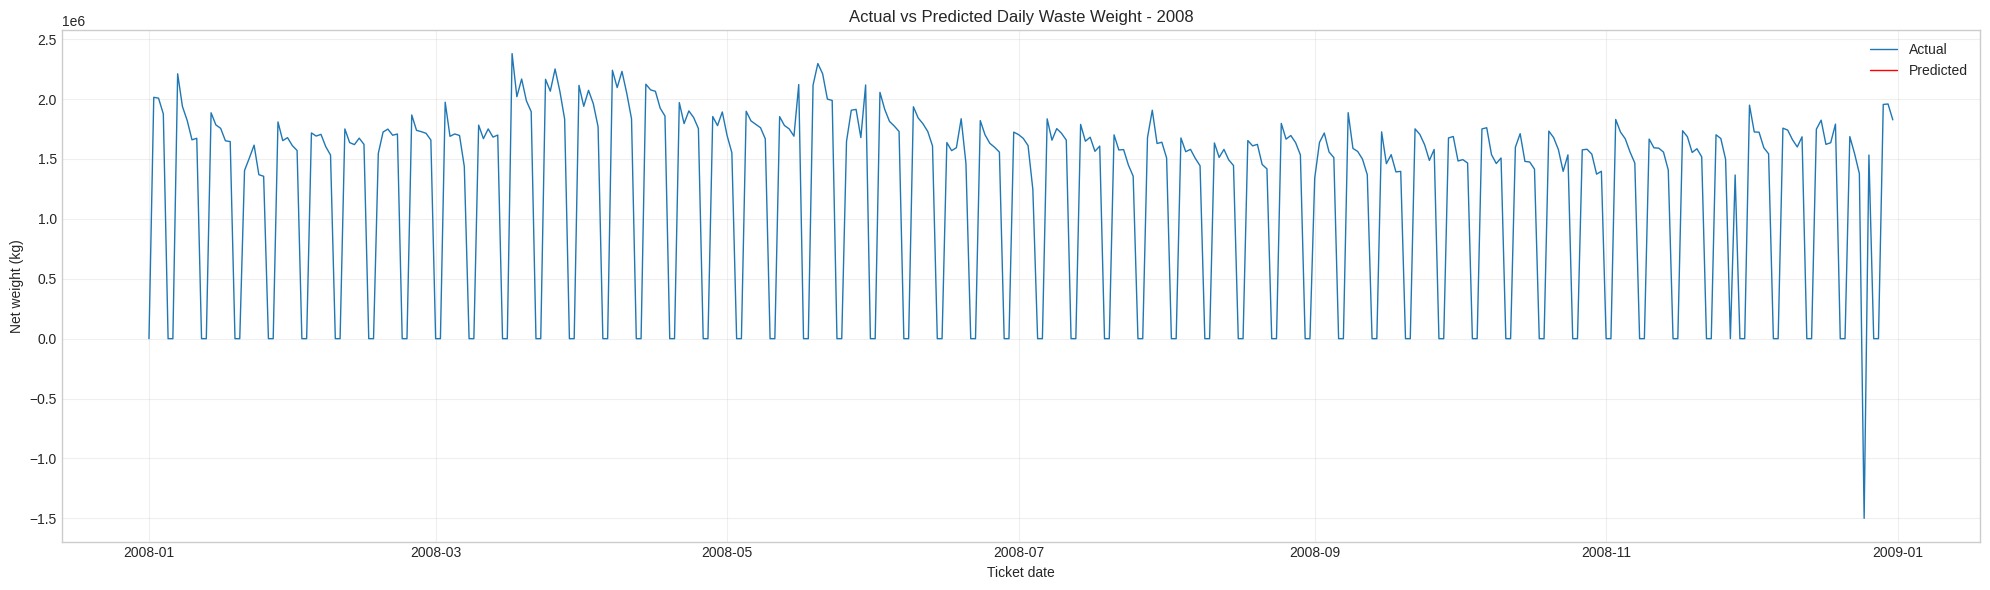

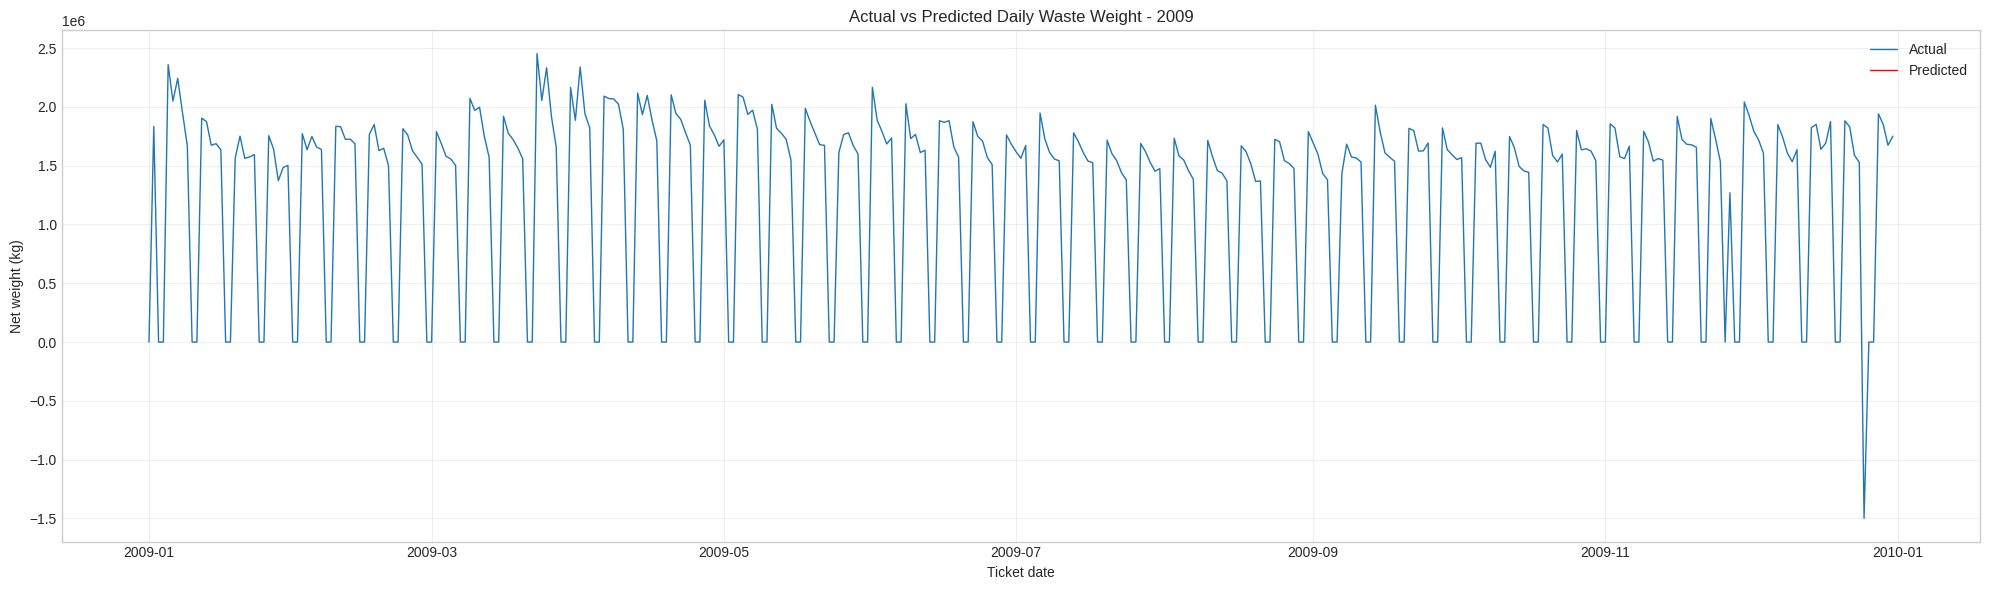

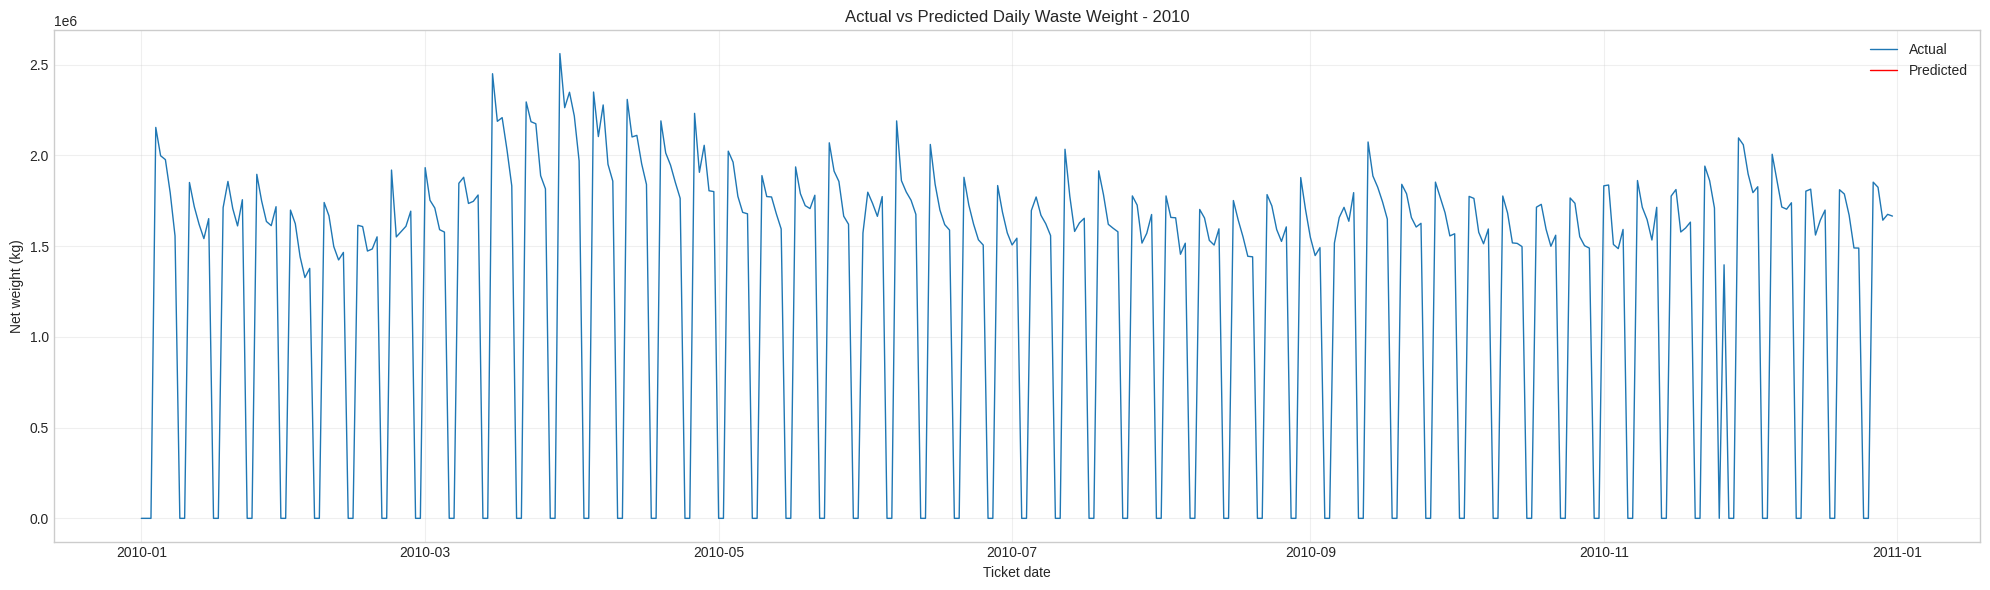

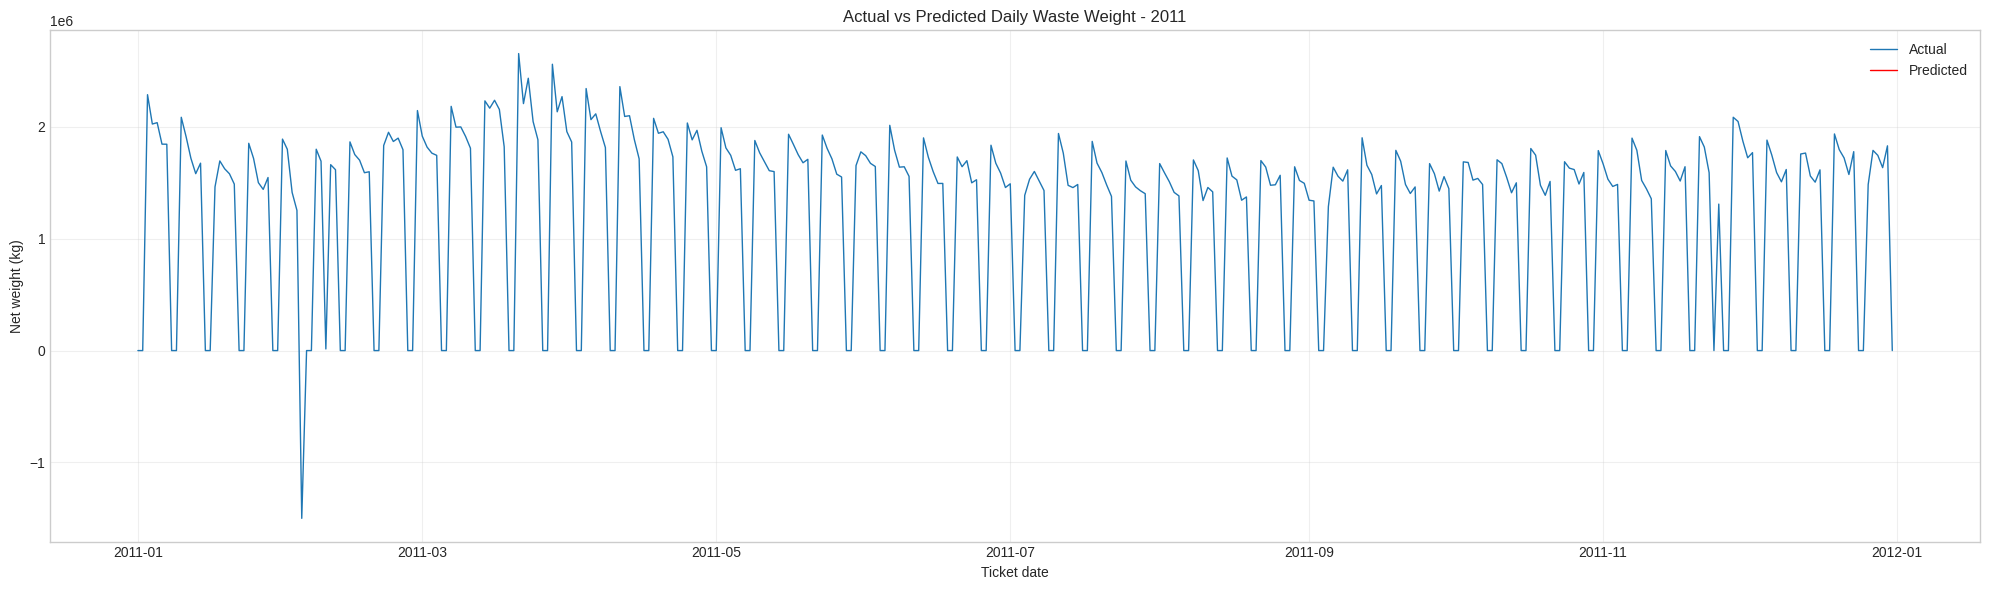

In [69]:
for year in range(2001, 2012):

    df_year = df[df['ticket_date'].dt.year == year].copy()

    if df_year.empty:
        print(f"No data available for {year}")
        continue

    plt.figure(figsize=(20, 6), dpi=100)

    # Actual waste weight
    plt.plot(
        df_year['ticket_date'],
        df_year['net_weight_kg'],
        label='Actual',
        linewidth=1
    )

    # Predicted waste weight
    plt.plot(
        df_year['ticket_date'],
        df_year['predicted_net_weight_kg'],
        color='red',
        label='Predicted',
        linewidth=1
    )

    plt.title(f'Actual vs Predicted Daily Waste Weight - {year}')
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Actual and Predicted Daily waste Data

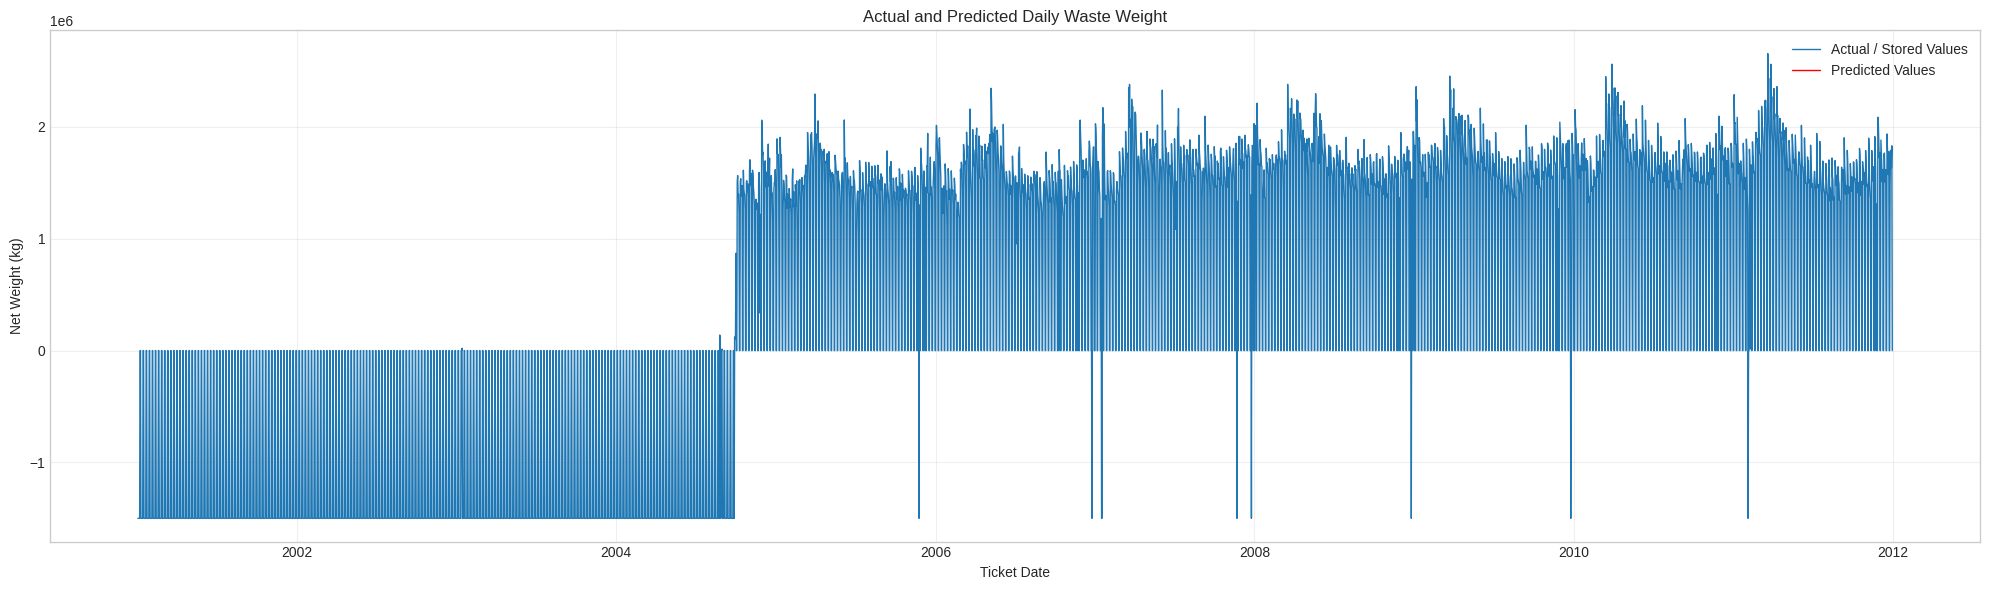

In [70]:
plt.figure(figsize=(20, 6))

plt.plot(
    df['ticket_date'],
    df['net_weight_kg'],
    label='Actual / Stored Values',
    linewidth=1
)

plt.plot(
    df['ticket_date'],
    df['predicted_net_weight_kg'],
    color='red',
    label='Predicted Values',
    linewidth=1
)

plt.title('Actual and Predicted Daily Waste Weight')
plt.xlabel('Ticket Date')
plt.ylabel('Net Weight (kg)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [71]:
df_backup = df.copy()
del df['predicted_net_weight_kg']

In [73]:
DAILY_WASTE_OUTPUT_DATA_FILE_PATH = '/content/daily_waste_output_Austin.csv'

df.to_csv(DAILY_WASTE_OUTPUT_DATA_FILE_PATH, index=False)

print("File saved successfully:", DAILY_WASTE_OUTPUT_DATA_FILE_PATH)

File saved successfully: /content/daily_waste_output_Austin.csv
